# SMARTFETCH
## Phase 1 – Problem Understanding, Dataset Creation and EDA

### Problem Statement

SmartFetch is a parcel delivery management and prediction
system designed to help customers receive their packages
at convenient delivery times.

The system uses machine learning to:

1. Predict the estimated delivery time of a package.
2. Predict whether a package will be delivered on time
   or delayed.

### Machine Learning Problems

1. Regression:
   Predict delivery_time_hours.

2. Classification:
   Predict delivery_status.

### Dataset

We will generate 1,000 synthetic logistics records
containing nine columns.

## 1.2 – Input and Target Variables

### Input Features (X)

1. distance_km
2. package_weight_kg
3. traffic_level
4. weather_condition
5. vehicle_type
6. warehouse_processing_hours

### Regression Target (y)

delivery_time_hours

### Classification Target (y)

delivery_status

### Identifier

package_id

package_id is used to identify individual packages.
It will not be used as an ML input feature.

In [1]:
# ==========================================
# 1.3 - IMPORT REQUIRED LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# For reproducibility
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ==========================================
# 1.4 - GENERATE SYNTHETIC LOGISTICS DATASET
# ==========================================

# Number of package records
num_records = 1000

# Generate package IDs
package_id = [
    f"PKG{str(i).zfill(4)}"
    for i in range(1, num_records + 1)
]

# Generate delivery distances
distance_km = np.random.uniform(
    2, 100, num_records
).round(2)

# Generate package weights
package_weight_kg = np.random.uniform(
    0.5, 30, num_records
).round(2)

# Generate traffic conditions
traffic_level = np.random.choice(
    ["Low", "Medium", "High"],
    num_records,
    p=[0.3, 0.45, 0.25]
)

# Generate weather conditions
weather_condition = np.random.choice(
    ["Clear", "Cloudy", "Rainy", "Stormy"],
    num_records,
    p=[0.4, 0.25, 0.25, 0.1]
)

# Generate vehicle types
vehicle_type = np.random.choice(
    ["Bike", "Van", "Truck"],
    num_records,
    p=[0.35, 0.45, 0.2]
)

# Generate warehouse processing hours
warehouse_processing_hours = np.random.uniform(
    0.5, 5, num_records
).round(2)


print("Synthetic logistics features generated!")

Synthetic logistics features generated!


In [3]:
# ==========================================
# 1.5 - GENERATE DELIVERY TIME
# ==========================================

# Average vehicle speeds in km per hour
vehicle_speeds = {
    "Bike": 25,
    "Van": 40,
    "Truck": 35
}

# Convert vehicle type into average speed
vehicle_speed = np.array([
    vehicle_speeds[vehicle]
    for vehicle in vehicle_type
])

# Traffic impact
traffic_impact = {
    "Low": 0.0,
    "Medium": 0.75,
    "High": 1.75
}

traffic_delay = np.array([
    traffic_impact[level]
    for level in traffic_level
])

# Weather impact
weather_impact = {
    "Clear": 0.0,
    "Cloudy": 0.25,
    "Rainy": 0.8,
    "Stormy": 1.5
}

weather_delay = np.array([
    weather_impact[weather]
    for weather in weather_condition
])

# Package handling time
handling_time = package_weight_kg * 0.015

# Calculate travel time
travel_time = distance_km / vehicle_speed

# Random variation
random_delay = np.random.normal(
    0, 0.3, num_records
)

# Calculate total delivery time
delivery_time_hours = (
    travel_time
    + warehouse_processing_hours
    + traffic_delay
    + weather_delay
    + handling_time
    + random_delay
)

# Avoid negative delivery times
delivery_time_hours = np.maximum(
    delivery_time_hours, 0.5
).round(2)

print("Delivery time generated successfully!")

Delivery time generated successfully!


In [4]:
# ==========================================
# 1.6 - GENERATE DELIVERY STATUS
# ==========================================

# Calculate expected delivery time
expected_delivery_time = (
    travel_time
    + warehouse_processing_hours
    + 1.5
)

# Determine delivery status
delivery_status = np.where(
    delivery_time_hours > expected_delivery_time,
    "Delayed",
    "On Time"
)

print("Delivery status generated successfully!")

Delivery status generated successfully!


In [6]:
from pathlib import Path

Path("../data").mkdir(parents=True, exist_ok=True)

In [8]:
# ==========================================
# 1.7 - CREATE DATAFRAME
# ==========================================

data = {
    "package_id": package_id,
    "distance_km": distance_km,
    "package_weight_kg": package_weight_kg,
    "traffic_level": traffic_level,
    "weather_condition": weather_condition,
    "vehicle_type": vehicle_type,
    "warehouse_processing_hours": warehouse_processing_hours,
    "delivery_time_hours": delivery_time_hours,
    "delivery_status": delivery_status
}

df = pd.DataFrame(data)

print("SmartFetch dataset created successfully!")

SmartFetch dataset created successfully!


In [9]:
# ==========================================
# 1.8 - SAVE DATASET
# ==========================================

df.to_csv(
    "../data/smartfetch_dataset.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [10]:
# ==========================================
# 1.9A - DISPLAY FIRST FIVE RECORDS
# ==========================================

df.head()

,package_id,distance_km,package_weight_kg,traffic_level,weather_condition,vehicle_type,warehouse_processing_hours,delivery_time_hours,delivery_status
0,PKG0001,38.70,5.96,Low,Rainy,Van,2.27,3.81,On Time
1,PKG0002,95.17,16.49,Low,Rainy,Truck,2.63,6.54,On Time
2,PKG0003,73.74,26.25,High,Clear,Van,4.35,8.42,Delayed
3,PKG0004,60.67,22.10,Low,Cloudy,Bike,2.03,5.33,On Time
4,PKG0005,17.29,24.29,Low,Cloudy,Bike,4.41,5.48,On Time


In [11]:
# ==========================================
# 1.9B - DISPLAY LAST FIVE RECORDS
# ==========================================

df.tail()

,package_id,distance_km,package_weight_kg,traffic_level,weather_condition,vehicle_type,warehouse_processing_hours,delivery_time_hours,delivery_status
995,PKG0996,10.98,19.88,High,Cloudy,Truck,3.58,6.12,Delayed
996,PKG0997,91.90,28.72,Low,Clear,Bike,2.76,6.91,On Time
997,PKG0998,15.41,2.53,Medium,Clear,Bike,3.94,5.33,On Time
998,PKG0999,95.12,2.18,Low,Cloudy,Truck,2.68,5.64,On Time
999,PKG1000,45.71,8.82,High,Clear,Van,1.17,4.21,Delayed


In [12]:
# ==========================================
# 1.9C - CHECK DATASET SHAPE
# ==========================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 9


In [13]:
# ==========================================
# 1.9D - CHECK COLUMN NAMES
# ==========================================

print(df.columns.tolist())

['package_id', 'distance_km', 'package_weight_kg', 'traffic_level', 'weather_condition', 'vehicle_type', 'warehouse_processing_hours', 'delivery_time_hours', 'delivery_status']


In [14]:
# ==========================================
# 1.9E - CHECK DATA TYPES
# ==========================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   package_id                  1000 non-null   object 
 1   distance_km                 1000 non-null   float64
 2   package_weight_kg           1000 non-null   float64
 3   traffic_level               1000 non-null   object 
 4   weather_condition           1000 non-null   object 
 5   vehicle_type                1000 non-null   object 
 6   warehouse_processing_hours  1000 non-null   float64
 7   delivery_time_hours         1000 non-null   float64
 8   delivery_status             1000 non-null   object 
dtypes: float64(4), object(5)
memory usage: 70.4+ KB


In [15]:
# ==========================================
# 1.9F - STATISTICAL SUMMARY
# ==========================================

df.describe()

,distance_km,package_weight_kg,warehouse_processing_hours,delivery_time_hours
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,50.045070,15.457040,2.743150,5.700740
std,28.629424,8.619665,1.301235,1.793287
min,2.450000,0.590000,0.530000,0.910000
25%,25.127500,7.615000,1.620000,4.380000
50%,50.685000,15.800000,2.705000,5.640000
75%,74.945000,22.935000,3.830000,7.000000
max,99.970000,29.980000,5.000000,11.410000


In [16]:
# ==========================================
# 1.9G - CATEGORICAL DATA SUMMARY
# ==========================================

df.describe(include="object")

,package_id,traffic_level,weather_condition,vehicle_type,delivery_status
count,1000,1000,1000,1000,1000
unique,1000,3,4,3,2
top,PKG0001,Medium,Clear,Van,On Time
freq,1,442,416,447,566


In [17]:
# ==========================================
# 1.10 - DATASET QUALITY CHECKS
# ==========================================

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:")
print(df.duplicated().sum())

# Check unique package IDs
print("\nUnique package IDs:")
print(df["package_id"].nunique())

# Check unique traffic categories
print("\nTraffic categories:")
print(df["traffic_level"].unique())

# Check unique weather categories
print("\nWeather categories:")
print(df["weather_condition"].unique())

# Check unique vehicle categories
print("\nVehicle categories:")
print(df["vehicle_type"].unique())

Missing values:
package_id                    0
distance_km                   0
package_weight_kg             0
traffic_level                 0
weather_condition             0
vehicle_type                  0
warehouse_processing_hours    0
delivery_time_hours           0
delivery_status               0
dtype: int64

Duplicate records:
0

Unique package IDs:
1000

Traffic categories:
['Low' 'High' 'Medium']

Weather categories:
['Rainy' 'Clear' 'Cloudy' 'Stormy']

Vehicle categories:
['Van' 'Truck' 'Bike']


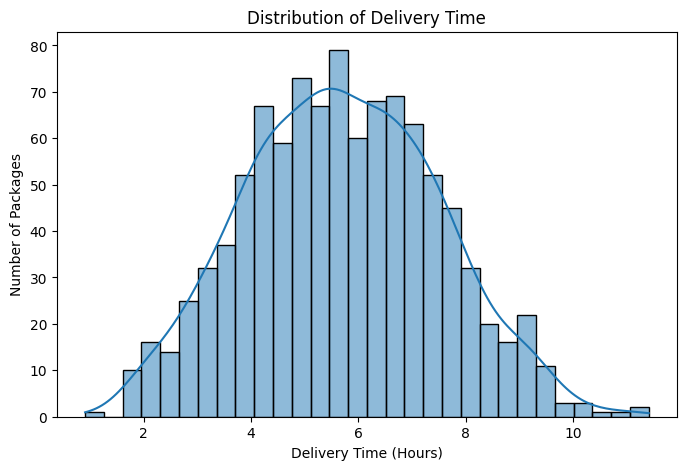

In [18]:
# ==========================================
# 1.11A - DELIVERY TIME DISTRIBUTION
# ==========================================

plt.figure(figsize=(8, 5))

sns.histplot(
    df["delivery_time_hours"],
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Hours)")
plt.ylabel("Number of Packages")

plt.show()

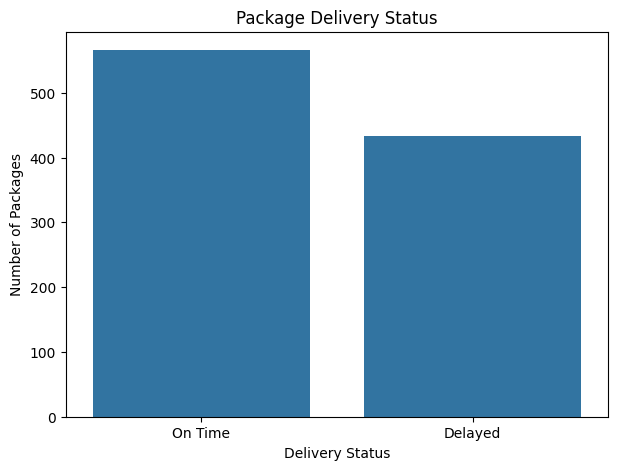

In [19]:
# ==========================================
# 1.11B - DELIVERY STATUS DISTRIBUTION
# ==========================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="delivery_status"
)

plt.title("Package Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Packages")

plt.show()

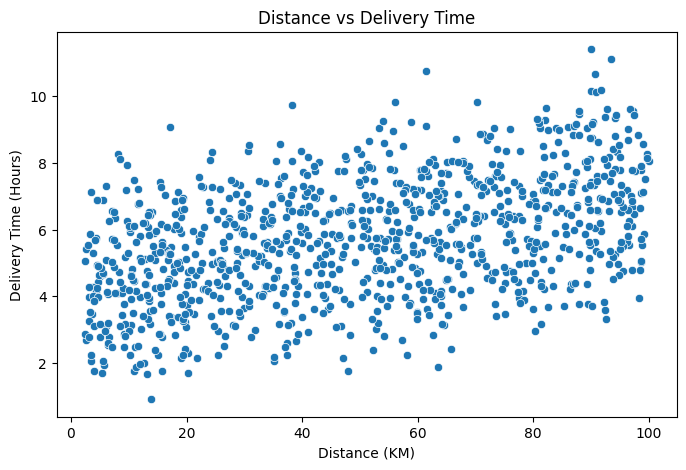

In [20]:
# ==========================================
# 1.11C - DISTANCE VS DELIVERY TIME
# ==========================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="distance_km",
    y="delivery_time_hours"
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (KM)")
plt.ylabel("Delivery Time (Hours)")

plt.show()

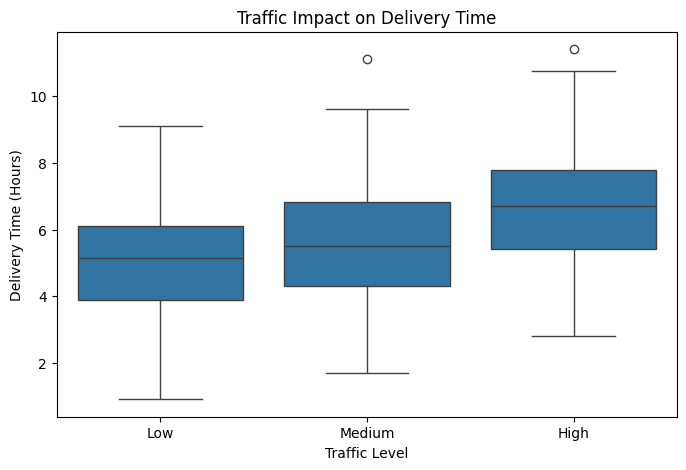

In [21]:
# ==========================================
# 1.11D - TRAFFIC VS DELIVERY TIME
# ==========================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="traffic_level",
    y="delivery_time_hours",
    order=["Low", "Medium", "High"]
)

plt.title("Traffic Impact on Delivery Time")
plt.xlabel("Traffic Level")
plt.ylabel("Delivery Time (Hours)")

plt.show()

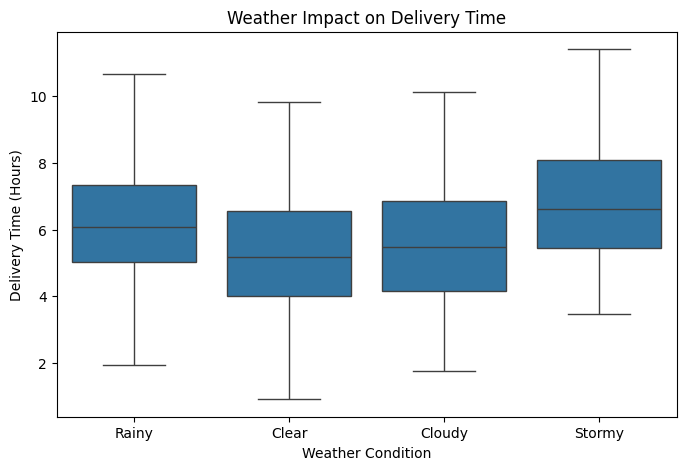

In [22]:
# ==========================================
# 1.11E - WEATHER VS DELIVERY TIME
# ==========================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="weather_condition",
    y="delivery_time_hours"
)

plt.title("Weather Impact on Delivery Time")
plt.xlabel("Weather Condition")
plt.ylabel("Delivery Time (Hours)")

plt.show()

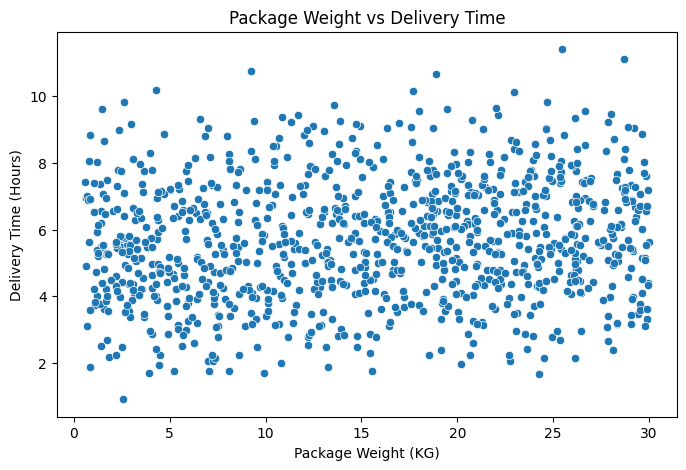

In [23]:
# ==========================================
# 1.11G - PACKAGE WEIGHT VS DELIVERY TIME
# ==========================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="package_weight_kg",
    y="delivery_time_hours"
)

plt.title("Package Weight vs Delivery Time")
plt.xlabel("Package Weight (KG)")
plt.ylabel("Delivery Time (Hours)")

plt.show()

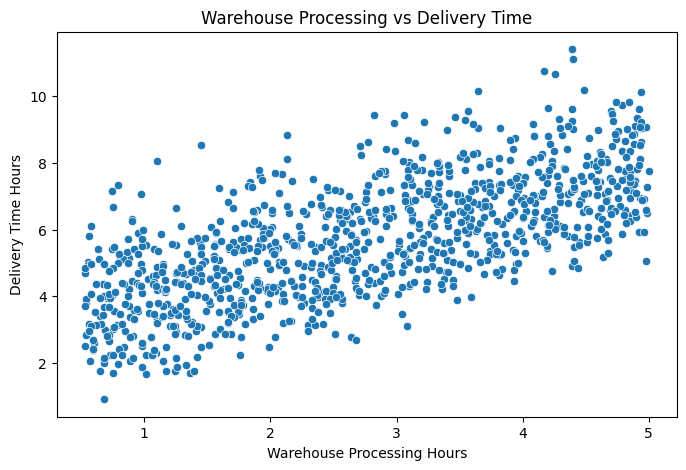

In [24]:
# ==========================================
# 1.11H - WAREHOUSE PROCESSING VS DELIVERY TIME
# ==========================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="warehouse_processing_hours",
    y="delivery_time_hours"
)

plt.title("Warehouse Processing vs Delivery Time")
plt.xlabel("Warehouse Processing Hours")
plt.ylabel("Delivery Time Hours")

plt.show()

# 1.12 - EDA OBSERVATIONS

After exploring the SmartFetch dataset, we expect
to investigate the following relationships:

1. Distance:
   Longer delivery distances generally increase
   delivery time.

2. Traffic:
   High traffic can increase delivery time.

3. Weather:
   Rainy and stormy conditions can affect delivery speed.

4. Vehicle Type:
   Different vehicles have different average speeds.

5. Package Weight:
   Heavier packages may require more handling time.

6. Warehouse Processing:
   Higher processing time increases total delivery time.

7. Delivery Status:
   Packages exceeding the generated delivery SLA
   are classified as delayed.

### Phase 1 Conclusion

We have created a synthetic logistics dataset
containing 1,000 records and nine columns.

We have explored the dataset using Pandas,
Matplotlib and Seaborn.

The dataset is ready for preprocessing and
machine learning preparation in Phase 2.